# Fixing the log readout — a construction that actually computes the log

Folder 14's "in-architecture construction" did **not** use the network's FFN: it zeroed `ff2`
and normalised the counts in closed form outside the model. That made it a *closed-form
baseline wearing the architecture's clothes*, and it is also why the broken frozen log readout
(`fit_log_core`: 2000 Adam steps at lr=1e-2 that diverge to MSE 4.0e+02) was never caught.

This notebook rebuilds the construction so that **every step happens inside the network**:

| stage | who does it | what it produces |
|---|---|---|
| layer-1 attention | hand-set `W_qk`, `W_ov` | previous-token channel |
| layer-2 attention | hand-set `W_qk`, `W_ov` | $f_v$ = empirical **frequency** of successor $v$ of the current state, written into residual coords `in2 … in2+V` |
| residual FFN `ff1→GELU→ff2` | hand-fitted GELU log core | turns $f_v$ into $\log(f_v+\varepsilon)$ **in place** (it must output $\log(f+\varepsilon)-f$, because the block is residual) |
| `fc_out` | identity selector + one constant bias | signal logit $=\log(f_v+\varepsilon)$, noise logit $=b$ |
| softmax | the model's own | the predictive distribution |

**Why a single constant noise bias is exact here.** Layer-2 attention is a softmax average, so
$\sum_v f_v = 1$ *identically* (verified below, not assumed). Hence
$S=\sum_v(f_v+\varepsilon)=1+V_\text{sig}\varepsilon$ is a constant, and putting

$$b \;=\; \log\frac{(1+V_\text{sig}\varepsilon)(1-\alpha)}{\alpha\, n_\text{noise}}$$

into `fc_out.bias` for the noise rows makes the model's own softmax return **exactly**

$$p(v)=\alpha\frac{f_v+\varepsilon}{1+V_\text{sig}\varepsilon}\ \ (v<V_\text{sig}),
\qquad p(\text{noise})=\frac{1-\alpha}{n_\text{noise}}.$$

No external renormalisation anywhere. Everything below is verified numerically before it is
plotted.

Data: folder 12's `dataset/` (25k train / 10k test per threshold). Trained models are *not*
touched here — this notebook is only about the reference curves.

## 0. Setup

In [1]:
import importlib.util, json, os, time
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ── EDIT HERE ────────────────────────────────────────────────────────────────
THRESHOLDS  = None        # None -> every data_x_*.pt present in folder 12's dataset;
                          # set an explicit list to restrict the sweep.
SPLITS      = ['train', 'test']
EPS         = 0.01        # smoothing inside the log: logit_v = log(f_v + EPS).
                          # folder-11/14 convention, kept so the numbers stay comparable.
K_LOG       = 128         # GELU units per signal state in the log core (== freeze_hidden_k)
CGAIN       = 32.0        # per-knot gain multiplier of the log core (grid-searched, see below)
DEVICE      = 'cuda:1' if torch.cuda.is_available() else 'cpu'
FWD_BATCH   = 256         # sequences per forward chunk
USE_CACHE   = True        # reuse artifacts/baselines_cache.json where possible
# ─────────────────────────────────────────────────────────────────────────────

_F12 = os.path.join('..', '12. training level exhaustive experiment to confirm finding')
_F14 = os.path.join('..', '14. elimination final convergence confusion')
DATA_DIR = os.path.join(_F12, 'dataset')

# the model class itself is imported from folder 14's train.py -- the construction must live in
# EXACTLY the architecture the trained models use, not in a re-typed copy of it.
_spec = importlib.util.spec_from_file_location('t14', os.path.join(_F14, 'train.py'))
_t14 = importlib.util.module_from_spec(_spec); _spec.loader.exec_module(_t14)
SimplifiedTransformerMLP = _t14.SimplifiedTransformerMLP

# ── one plotting style for the whole notebook, so no figure has to set sizes locally ──
plt.rcParams.update({
    'figure.dpi':        110,     # on-screen
    'savefig.dpi':       170,     # written to artifacts/
    'font.size':          13,
    'axes.titlesize':     14,
    'axes.labelsize':     13,
    'xtick.labelsize':    12,
    'ytick.labelsize':    12,
    'legend.fontsize':    12,
    'figure.titlesize':   16,
    'axes.titlepad':       9,
    'axes.grid':        True,
    'grid.alpha':       0.25,
    'axes.spines.top':  False,
    'axes.spines.right': False,
    'lines.linewidth':   2.0,
    'legend.frameon':   False,
    'figure.constrained_layout.use': True,
})

DEV = torch.device(DEVICE)
ARTIFACTS = 'artifacts'
os.makedirs(ARTIFACTS, exist_ok=True)

def load_blob(split, thr):
    return torch.load(os.path.join(DATA_DIR, split, f'data_x_{thr}.pt'), weights_only=False)

def discover_thresholds(data_dir=DATA_DIR, splits=('train', 'test')):
    """Every threshold present in ALL splits -- so a partially-regenerated dataset can never
    silently drop a curve from one panel but not the other."""
    import glob as _glob
    sets = [{float(os.path.basename(p)[7:-3])
             for p in _glob.glob(os.path.join(data_dir, s, 'data_x_*.pt'))} for s in splits]
    common = sorted(set.intersection(*sets))
    missing = sorted(set.union(*sets) - set(common))
    if missing:
        print(f'[warn] present in only some splits, skipped: {missing}')
    return common

if THRESHOLDS is None:
    THRESHOLDS = discover_thresholds()

_b = load_blob('test', THRESHOLDS[0])
V, VS, T = _b['total_vocab'], _b['vocab_set1'], _b['seq_len']
N_NOISE  = V - VS
TOKEN_START, TOKEN_END = T // 2, T          # score the last 50 tokens, as everywhere else
print(f'device      : {DEV}')
print(f'data        : {DATA_DIR}')
print(f'vocab       : V={V} (signal {VS} + noise {N_NOISE}), seq_len={T}, '
      f'scored window [{TOKEN_START}:{TOKEN_END}]')
print(f'sizes       : train {load_blob("train", THRESHOLDS[0])["x"].shape[0]}, '
      f'test {_b["x"].shape[0]} sequences per threshold')
print(f'thresholds  : {THRESHOLDS}')
del _b

device      : cuda:1
data        : ../12. training level exhaustive experiment to confirm finding/dataset
vocab       : V=8 (signal 4 + noise 4), seq_len=100, scored window [50:100]


sizes       : train 25000, test 10000 sequences per threshold
thresholds  : [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]


## 1. The log core — fit it properly, then prove it

The FFN block is **residual**: `s = s + ff2(GELU(ff1(s)))`. Coordinate `in2+v` arrives holding
$f_v$ and must leave holding $\log(f_v+\varepsilon)$, so the core has to represent

$$g(f)\;=\;\log(f+\varepsilon)-f,\qquad f\in[0,1].$$

Each signal state gets its own block of `K_LOG` GELU units, $\mathrm{GELU}(a_j f + b_j)$ with
$b_j=-a_j p_j$, so $p_j$ is the knot where unit $j$ turns on.

Two things folder 12/14's `fit_log_core` got wrong and this one does not:

1. **Knot placement.** $g$ has all its curvature at small $f$ ($g''=-(f+\varepsilon)^{-2}$).
   Uniform knots waste 128 units on the flat part. Knots geometric in $(f+\varepsilon)$ make the
   local approximation error scale-free.
2. **The fit itself.** Once the knots and gains are fixed the problem is **linear** in the
   output weights, so `lstsq` gives the global optimum. The old code took that optimum and then
   ran 2000 Adam steps at lr=1e-2 on top of it, which diverged. Here there is no gradient
   refinement at all — there is nothing left to refine.

`CGAIN` (the only free knob: gain $a_j =$ `CGAIN`$/h_j$, with $h_j$ the local knot spacing) was
chosen by the grid below and is then hardcoded, per the usual convention in this project.

In [2]:
def fit_log_core(eps, k, cgain, fmax=1.0, n_grid=20001):
    '''Least-squares GELU representation of  g(f) = log(f+eps) - f  on [0, fmax].

    Returns (a, b, w, c, max_abs_err, mse) with
        g(f) ~ GELU(f*a + b) @ w + c            a,b: [k]   w: [k]   c: scalar
    Knots are geometric in (f+eps); gain_j = cgain / (local knot spacing). Everything is done
    in float64 and only the final tensors are cast to float32.
    '''
    kn = torch.exp(torch.linspace(np.log(eps), np.log(fmax + eps), k,
                                  dtype=torch.float64)) - eps
    h  = torch.diff(kn, prepend=(2 * kn[:1] - kn[1:2])).clamp_min(1e-12)
    a  = cgain / h
    b  = -a * kn
    fg = (torch.exp(torch.linspace(np.log(eps), np.log(fmax + eps), n_grid,
                                   dtype=torch.float64)) - eps).clamp_min(0.0)
    basis  = F.gelu(fg.unsqueeze(1) * a.unsqueeze(0) + b.unsqueeze(0))
    basis1 = torch.cat([basis, torch.ones(n_grid, 1, dtype=torch.float64)], 1)
    tgt    = torch.log(fg + eps) - fg
    sol    = torch.linalg.lstsq(basis1, tgt.unsqueeze(1)).solution.squeeze(1)
    w, c   = sol[:k], sol[k]
    err    = (basis @ w + c - tgt).abs()
    return (a.float(), b.float(), w.float(), float(c),
            float(err.max()), float((err ** 2).mean()))

# ── the grid search behind CGAIN=32 (cheap; kept visible rather than hidden in a script) ──
print(f'{"knots":>6s} {"cgain":>7s} {"max|err|":>10s} {"mse":>10s}   (target: max|err| << 1e-2)')
for kind in ('uniform', 'geometric'):
    for cg in (2.0, 4.0, 8.0, 16.0, 32.0, 64.0):
        if kind == 'uniform':      # the old scheme, for contrast
            kn = torch.linspace(0, 1, K_LOG, dtype=torch.float64)
            a  = torch.full((K_LOG,), cg * (K_LOG - 1), dtype=torch.float64)
            b  = -a * kn
            fg = torch.linspace(0, 1, 20001, dtype=torch.float64)
            bs = F.gelu(fg.unsqueeze(1) * a + b)
            b1 = torch.cat([bs, torch.ones(20001, 1, dtype=torch.float64)], 1)
            tg = torch.log(fg + EPS) - fg
            s  = torch.linalg.lstsq(b1, tg.unsqueeze(1)).solution.squeeze(1)
            e  = (bs @ s[:K_LOG] + s[K_LOG] - tg).abs()
            mx, ms = float(e.max()), float((e ** 2).mean())
        else:
            *_, mx, ms = fit_log_core(EPS, K_LOG, cg)
        print(f'{kind:>9s} {cg:7.1f} {mx:10.3e} {ms:10.3e}')

LOG_A, LOG_B, LOG_W, LOG_C, LOG_MAXERR, LOG_MSE = fit_log_core(EPS, K_LOG, CGAIN)
print(f'\nchosen: geometric knots, CGAIN={CGAIN}  ->  max|err|={LOG_MAXERR:.3e} nats, '
      f'mse={LOG_MSE:.3e}')

 knots   cgain   max|err|        mse   (target: max|err| << 1e-2)


  uniform     2.0  7.033e-02  4.615e-06


  uniform     4.0  5.410e-02  2.063e-06


  uniform     8.0  4.096e-02  1.599e-06


  uniform    16.0  3.599e-02  1.630e-06


  uniform    32.0  3.451e-02  1.672e-06


... (4 outputs left out)

geometric    16.0  2.211e-04  2.792e-09


geometric    32.0  1.382e-04  2.526e-09


geometric    64.0  1.198e-04  2.449e-09



chosen: geometric knots, CGAIN=32.0  ->  max|err|=1.382e-04 nats, mse=2.526e-09


In [3]:
# ── hard checks on the fitted core, in float32 exactly as the model will run it ──────────
def core_eval(f):
    '''g_hat(f) in float32, the same computation the FFN performs.'''
    f = torch.as_tensor(f, dtype=torch.float32).reshape(-1, 1)
    return F.gelu(f * LOG_A.unsqueeze(0) + LOG_B.unsqueeze(0)) @ LOG_W + LOG_C

# (a) every frequency the induction head can actually emit is a/b with b <= T-1
f_real = torch.tensor(sorted({0.0} | {a / b for b in range(1, T) for a in range(0, b + 1)}),
                      dtype=torch.float32)
err_real = (core_eval(f_real) + f_real - torch.log(f_real + EPS)).abs()
imp_real = core_eval(f_real) + f_real
d_real   = torch.diff(imp_real)
# (b) a dense grid, to catch anything between the realizable values
f_dense = torch.linspace(0, 1, 100001)
err_dense = (core_eval(f_dense) + f_dense - torch.log(f_dense + EPS)).abs()
implied = core_eval(f_dense) + f_dense
# monotonicity of the FITTED FUNCTION is a float64 question -- on the 1e-5 dense grid the true
# increment is only ~1e-5, i.e. at the level of float32 roundoff on a 128-term sum, so a float32
# test there measures arithmetic noise, not the fit. It is therefore checked twice: in float64 on
# the dense grid (is the function monotone at all?) and in float32 on the realizable values (is
# it monotone at the resolution the model will actually see?).
f64 = torch.linspace(0, 1, 100001, dtype=torch.float64)
imp64 = (F.gelu(f64.unsqueeze(1) * LOG_A.double() + LOG_B.double()) @ LOG_W.double()
         + LOG_C) + f64
mono64  = bool((torch.diff(imp64) > 0).all())
mono32r = bool((d_real > 0).all())

print(f'realizable f = a/b, b<{T}   ({len(f_real)} values): max|err| = {err_real.max():.3e} nats')
print(f'dense grid f in [0,1] (1e5 values): max|err| = {err_dense.max():.3e} nats')
print(f'monotone, float64 on the dense grid          : {mono64}  '
      f'(min increment {float(torch.diff(imp64).min()):.2e})')
print(f'monotone, float32 on the realizable f values : {mono32r}  '
      f'(min increment {float(d_real.min()):.2e}; '
      f'closest realizable pair is {float(torch.diff(f_real).min()):.1e} apart)')
print()
print(f'{"f":>8s} {"log(f+eps)":>12s} {"realised":>12s} {"err":>10s}')
for v in (0.0, 0.005, 0.01, 0.02, 0.05, 0.1, 0.25, 0.5, 0.75, 1.0):
    r = float(core_eval([v])[0] + v)
    print(f'{v:8.3f} {np.log(v + EPS):12.5f} {r:12.5f} {r - np.log(v + EPS):10.2e}')

assert err_dense.max() < 1e-2, 'log core is not accurate enough to be called a log'
assert mono64,  'the fitted core is not a monotone function of f'
assert mono32r, 'the core is not monotone at the resolution the model actually sees'
print('\nOK - the core represents log(f+eps) to better than 1e-2 nats everywhere, monotonically.')

realizable f = a/b, b<100   (3005 values): max|err| = 1.383e-04 nats
dense grid f in [0,1] (1e5 values): max|err| = 1.410e-04 nats
monotone, float64 on the dense grid          : True  (min increment 9.08e-06)
monotone, float32 on the realizable f values : True  (min increment 8.89e-05; closest realizable pair is 1.0e-04 apart)

       f   log(f+eps)     realised        err
   0.000     -4.60517     -4.60503   1.38e-04
   0.005     -4.19971     -4.19968   2.19e-05
   0.010     -3.91202     -3.91196   6.50e-05
   0.020     -3.50656     -3.50657  -7.67e-06
   0.050     -2.81341     -2.81344  -2.98e-05
   0.100     -2.20727     -2.20717   1.06e-04
   0.250     -1.34707     -1.34711  -4.09e-05
   0.500     -0.67334     -0.67333   1.23e-05
   0.750     -0.27444     -0.27442   1.32e-05
   1.000      0.00995      0.01008   1.32e-04

OK - the core represents log(f+eps) to better than 1e-2 nats everywhere, monotonically.


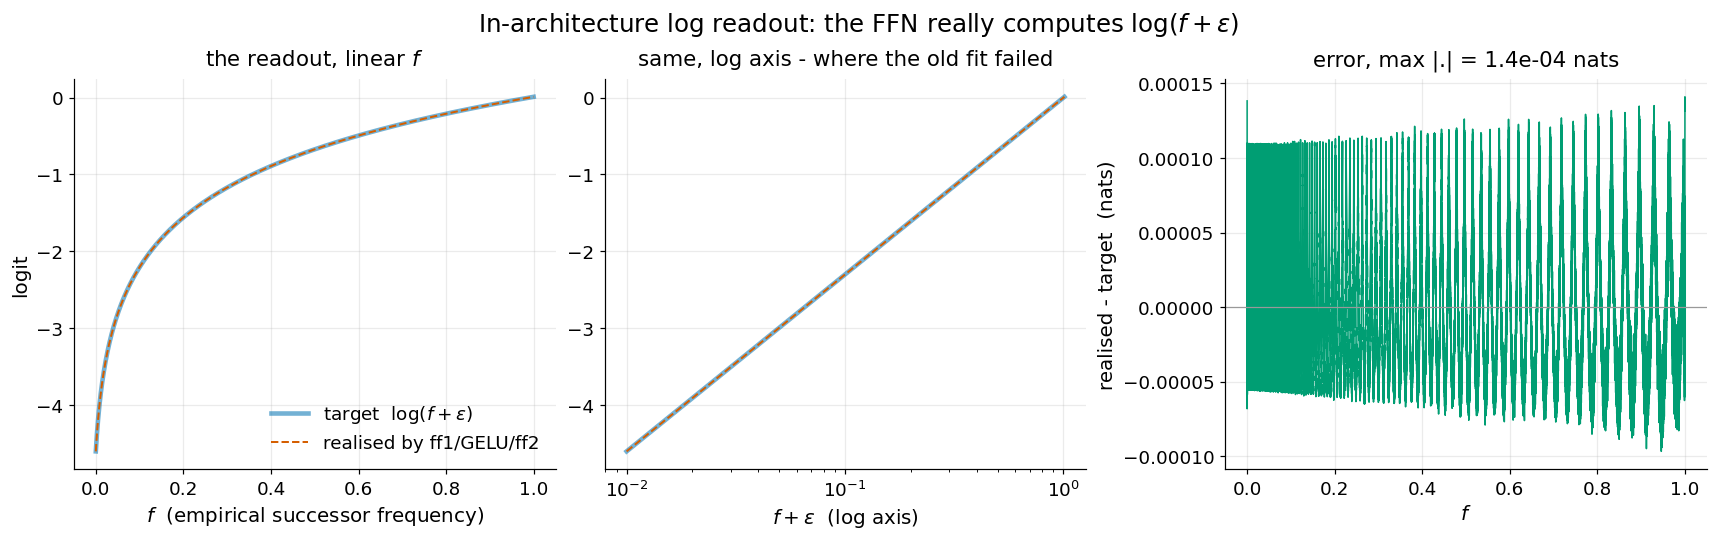

In [4]:
# ── figure: the core against its target, and the residual error ─────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.8))
fd = f_dense.numpy(); realised = implied.numpy(); tgt = np.log(fd + EPS)

axes[0].plot(fd, tgt, color='#0072B2', lw=3, alpha=.55, label=r'target  $\log(f+\varepsilon)$')
axes[0].plot(fd, realised, color='#D55E00', lw=1.3, ls='--', label='realised by ff1/GELU/ff2')
axes[0].set_xlabel('$f$  (empirical successor frequency)'); axes[0].set_ylabel('logit')
axes[0].set_title('the readout, linear $f$'); axes[0].legend(loc='lower right')

axes[1].plot(fd + EPS, tgt, color='#0072B2', lw=3, alpha=.55)
axes[1].plot(fd + EPS, realised, color='#D55E00', lw=1.3, ls='--')
axes[1].set_xscale('log'); axes[1].set_xlabel(r'$f+\varepsilon$  (log axis)')
axes[1].set_title('same, log axis - where the old fit failed')

axes[2].plot(fd, (realised - tgt), color='#009E73', lw=1.0)
axes[2].axhline(0, color='0.6', lw=.8)
axes[2].set_xlabel('$f$'); axes[2].set_ylabel('realised - target  (nats)')
axes[2].set_title(f'error, max |.| = {float(err_dense.max()):.1e} nats')
fig.suptitle('In-architecture log readout: the FFN really computes '
             '$\\log(f+\\varepsilon)$')
fig.savefig(os.path.join(ARTIFACTS, 'log_core_fit.png'), bbox_inches='tight')
plt.show()

## 2. The construction

`_build_construction_attn` is folder 10's `PerfectInductionTransformer` circuit collapsed into
the combined parametrisation ($W_{qk}=W_q^\top W_k$, $W_{ov}=W_v^\top W_o^\top$ — an exact
reparametrisation). Nothing about it changes here; what changes is everything downstream of it.

In [5]:
def _build_construction_attn(V, T, Vs, dev):
    '''Hand-set combined Wqk/Wov implementing the perfect induction circuit.'''
    D = V + T
    Wq1 = torch.eye(D, device=dev) * (D ** 0.5)
    T1 = torch.zeros(D, D, device=dev)
    for k in range(Vs, V): T1[k, :] = -1e9                     # noise tokens are never queried
    for tq in range(T):
        for tk in range(T):
            T1[V + tk, V + tq] = -1e9 if tq == tk else -20.0 * (tq - tk)   # attend to t-1
    Wk1 = T1.t()
    Wv1 = torch.zeros(D, D, device=dev); Wv1[:V, :V] = torch.eye(V, device=dev)
    Wo1 = torch.eye(D, device=dev)
    in2 = D + D
    Wq2 = torch.zeros(D, in2, device=dev)
    Wq2[:Vs, :Vs]    = torch.eye(Vs, device=dev) * (D ** 0.5) * 1000.0
    Wq2[:Vs, D:D+Vs] = torch.eye(Vs, device=dev) * (D ** 0.5) * 50.0
    for v in range(V): Wq2[Vs, v] = (D ** 0.5) * 10.0
    Wk2 = torch.zeros(D, in2, device=dev); Wk2[:V, D:D+V] = torch.eye(V, device=dev)
    for v in range(Vs, V): Wk2[Vs, v] = -50000.0
    Wv2 = torch.zeros(D, in2, device=dev); Wv2[:V, :V] = torch.eye(V, device=dev)
    Wo2 = torch.eye(D, device=dev)
    return Wq1.t() @ Wk1, Wv1.t() @ Wo1.t(), Wq2.t() @ Wk2, Wv2.t() @ Wo2.t()


def noise_bias(alpha, eps=EPS, Vs=VS, n_noise=N_NOISE):
    '''The single constant that makes the model's own softmax split alpha / (1-alpha).
    At alpha=1 the exact value is -inf; -30 is used instead (exp(-30)=9e-14, i.e. it moves the
    signal mass by 4e-13 -- far below float32 resolution -- and thr=1.0 has no noise tokens).'''
    if alpha >= 1.0:
        return -30.0
    return float(np.log((1 + Vs * eps) * (1 - alpha) / (alpha * n_noise)))


def build_construction_model(alpha, dev=DEV, eps=EPS, k=K_LOG, log_core=None):
    '''The full hand-built model: attention circuit + REAL log FFN + selector readout.'''
    a, b, w, c = log_core if log_core is not None else (LOG_A, LOG_B, LOG_W, LOG_C)
    a, b, w = a.to(dev), b.to(dev), w.to(dev)
    m = SimplifiedTransformerMLP(V, T, V + T, VS, k, bias=True, attn_param='combined').to(dev)
    Wqk1, Wov1, Wqk2, Wov2 = _build_construction_attn(V, T, VS, dev)
    with torch.no_grad():
        m.layer1.W_qk.copy_(Wqk1); m.layer1.W_ov.copy_(Wov1)
        m.layer2.W_qk.copy_(Wqk2); m.layer2.W_ov.copy_(Wov2)

        # ── the FFN: one block of k GELU units per signal state, computing log(f_v+eps)-f_v ──
        m.ff1.weight.zero_(); m.ff1.bias.zero_()
        m.ff2.weight.zero_(); m.ff2.bias.zero_()
        for v in range(VS):
            rows = slice(v * k, (v + 1) * k)
            m.ff1.weight[rows, m.in2 + v] = a      # read f_v ...
            m.ff1.bias[rows]              = b
            m.ff2.weight[m.in2 + v, rows] = w      # ... write log(f_v+eps)-f_v back in place
            m.ff2.bias[m.in2 + v]         = c

        # ── the readout: identity selector for the signal logits, one bias for the noise ──
        m.fc_out.weight.zero_(); m.fc_out.bias.zero_()
        m.fc_out.weight[:VS, m.in2:m.in2 + VS] = torch.eye(VS, device=dev)
        m.fc_out.bias[VS:] = noise_bias(alpha, eps)
    for p in m.parameters(): p.requires_grad_(False)
    m.eval()
    return m

_m = build_construction_model(0.6, dev=torch.device('cpu'))
n_used = int((_m.ff1.weight.abs().sum(1) > 0).sum())
print(f'construction model built: {sum(p.numel() for p in _m.parameters()):,} parameters')
print(f'  ff1 hidden units used : {n_used} / {_m.ff1.out_features}  '
      f'({VS} states x {K_LOG})')
print(f'  ff2 writes to coords  : {sorted(torch.where(_m.ff2.weight.abs().sum(1) > 0)[0].tolist())}'
      f'   (in2={_m.in2})')
print(f'  fc_out non-zero cells : {int((_m.fc_out.weight != 0).sum())} '
      f'(the {VS}x{VS} identity block at columns {_m.in2}:{_m.in2 + VS})')
print(f'  fc_out.bias           : {np.round(_m.fc_out.bias.numpy(), 4)}')
del _m

construction model built: 428,524 parameters
  ff1 hidden units used : 512 / 512  (4 states x 128)
  ff2 writes to coords  : [216, 217, 218, 219]   (in2=216)
  fc_out non-zero cells : 4 (the 4x4 identity block at columns 216:220)
  fc_out.bias           : [ 0.      0.      0.      0.     -1.7525 -1.7525 -1.7525 -1.7525]


### 2.1 The premise the constant noise bias rests on

The claim $\sum_v f_v \equiv 1$ is not an assumption — it follows from layer-2 being a softmax
average, and it is checked directly here, together with "the noise slots are exactly zero",
which is what makes the identity selector legitimate.

In [6]:
_blob = load_blob('test', 0.6)
_probe = build_construction_model(0.6, dev=torch.device('cpu'))
with torch.no_grad():   # temporarily silence FFN + readout to look at the raw layer-2 output
    _probe.ff1.weight.zero_(); _probe.ff1.bias.zero_()
    _probe.ff2.weight.zero_(); _probe.ff2.bias.zero_()
    _probe.fc_out.weight.zero_(); _probe.fc_out.bias.zero_()
    _probe.fc_out.weight[:V, _probe.in2:_probe.in2 + V] = torch.eye(V)
    raw = _probe(_blob['x'][:1024])[:, TOKEN_START:TOKEN_END]
f_sig, f_noise = raw[..., :VS], raw[..., VS:V]
S = f_sig.sum(-1)
print(f'signal slots f_v  : min {f_sig.min():.6f}  max {f_sig.max():.6f}')
print(f'noise  slots      : max |.| = {f_noise.abs().max():.3e}   (must be 0)')
print(f'sum_v f_v         : min {S.min():.8f}  max {S.max():.8f}   '
      f'max|sum-1| = {float((S - 1).abs().max()):.3e}')
print(f'f quantiles (0,10,50,90,100%): '
      f'{np.round(np.quantile(f_sig.numpy(), [0, .1, .5, .9, 1]), 4)}')
assert float((S - 1).abs().max()) < 1e-5, 'sum_v f_v is not 1 -- the constant noise bias is invalid'
assert float(f_noise.abs().max()) == 0.0
print('\nOK - sum_v f_v == 1 exactly, so a constant noise bias gives the exact alpha split.')
del _probe, _blob, raw, f_sig, f_noise

signal slots f_v  : min 0.000000  max 1.000000
noise  slots      : max |.| = 0.000e+00   (must be 0)
sum_v f_v         : min 0.99999946  max 1.00000060   max|sum-1| = 5.960e-07
f quantiles (0,10,50,90,100%): [0.     0.     0.0588 0.76   1.    ]

OK - sum_v f_v == 1 exactly, so a constant noise bias gives the exact alpha split.


### 2.2 The construction's CE, and proof that the network does the arithmetic

`construction_ce` runs the model and takes `F.cross_entropy` on its **raw logits** — the model's
own softmax, no post-processing. To show this is not accidentally right, it is compared against
the closed form $\alpha(f_v+\varepsilon)/\sum_u(f_u+\varepsilon)$ evaluated on the very same
$f$. Agreement to $\sim10^{-6}$ nats means the FFN, the selector and the softmax genuinely
reproduce the intended predictor.

In [7]:
_RAW_CACHE = {}

@torch.no_grad()
def raw_f(x, dev=DEV):
    '''The frequencies layer-2 attention writes, read straight out of the residual stream with
    the FFN and readout switched off -- the ground truth the log core is judged against.'''
    key = str(dev)
    if key not in _RAW_CACHE:
        m = build_construction_model(0.5, dev=dev)
        with torch.no_grad():
            m.ff1.weight.zero_(); m.ff1.bias.zero_()
            m.ff2.weight.zero_(); m.ff2.bias.zero_()
            m.fc_out.weight.zero_(); m.fc_out.bias.zero_()
            m.fc_out.weight[:V, m.in2:m.in2 + V] = torch.eye(V, device=dev)
        _RAW_CACHE[key] = m
    return _RAW_CACHE[key](x)[:, TOKEN_START:TOKEN_END, :VS].clamp_min(0.0)


@torch.no_grad()
def construction_ce(blob, alpha, dev=DEV, batch=FWD_BATCH, eps=EPS, also_closed_form=False):
    '''CE of the hand construction, read straight off the model's own softmax.'''
    m = build_construction_model(alpha, dev=dev, eps=eps)
    x_all, y_all = blob['x'], blob['y']
    tot, n = 0.0, 0
    tot_cf = 0.0
    for i in range(0, x_all.shape[0], batch):
        x = x_all[i:i + batch].to(dev); y = y_all[i:i + batch, TOKEN_START:TOKEN_END].to(dev)
        logits = m(x)[:, TOKEN_START:TOKEN_END]
        tot += F.cross_entropy(logits.reshape(-1, V), y.reshape(-1),
                               reduction='sum').item()
        n   += y.numel()
        if also_closed_form:
            # f is read from the RAW layer-2 attention output, NOT recovered as exp(logit)-eps.
            # Recovering it from the logits would make this check circular: it would confirm the
            # softmax + bias normalise correctly but would silently inherit whatever error the
            # log core made. Reading f independently makes the comparison a genuine end-to-end
            # test of the log as well.
            f = raw_f(x, dev=dev)
            psig = alpha * (f + eps) / (f + eps).sum(-1, keepdim=True)
            pn = torch.full(psig.shape[:-1] + (N_NOISE,), (1 - alpha) / N_NOISE, device=dev) \
                 if alpha < 1 else torch.zeros(psig.shape[:-1] + (N_NOISE,), device=dev)
            p = torch.cat([psig, pn], -1)
            tot_cf += -torch.log(p.gather(-1, y.unsqueeze(-1)).clamp_min(1e-12)).sum().item()
    return (tot / n, tot_cf / n) if also_closed_form else tot / n

print('in-arch CE = the model\'s own softmax;  closed form = alpha(f+eps)/sum(f+eps)\n'
      'with f read independently from the raw attention output.\n')
print(f'{"thr":>5s} {"in-arch CE":>12s} {"closed form":>12s} {"diff":>11s}')
for thr in THRESHOLDS:
    blob = load_blob('test', thr)
    sub = {**blob, 'x': blob['x'][:2048], 'y': blob['y'][:2048]}
    a, c = construction_ce(sub, thr, also_closed_form=True)
    print(f'{thr:5.1f} {a:12.6f} {c:12.6f} {a - c:+11.2e}')
    assert abs(a - c) < 1e-4, f'in-architecture readout disagrees with the closed form at {thr}'
print('\nOK - the network itself produces the intended distribution.')

in-arch CE = the model's own softmax;  closed form = alpha(f+eps)/sum(f+eps)
with f read independently from the raw attention output.

  thr   in-arch CE  closed form        diff


  0.4     1.794377     1.794376   +9.35e-07


  0.5     1.731546     1.731545   +1.01e-06


  0.6     1.623463     1.623462   +8.96e-07


  0.7     1.483587     1.483585   +1.75e-06


  0.8     1.289528     1.289526   +1.98e-06


  0.9     1.033587     1.033585   +2.12e-06


  1.0     0.631313     0.631310   +2.45e-06

OK - the network itself produces the intended distribution.


## 3. The three reference predictors

Unchanged from the earlier analysis (ported verbatim so the curves stay comparable):

- **ideal-$\alpha$** — knows the true 2-successor table *and* its split $q$. The CE floor; no
  context-only predictor can beat it.
- **true Bayes** — the exact posterior predictive for *this* generator: enumerate the 6
  unordered successor pairs, drop every pair that misses an observed successor (so impossible
  tokens get exactly zero mass), weight the survivors by $\int q^{n_a}(1-q)^{n_b}\,dq$ over
  $q\sim U(0.1,0.9)$, average. The best any context-only predictor can do.
- **ctx-count** — empirical counts $+\,\varepsilon$, renormalised, times $\alpha$, plus the exact
  noise floor. What a perfect induction head with a naive readout gives.

Note the two $\varepsilon$'s are not the same estimator. ctx-count smooths the **counts** by
$\varepsilon$; the construction smooths the **frequencies** by $\varepsilon$, which is
add-$(n\varepsilon)$ on counts. That difference is the whole reason the two curves separate.

In [8]:
import functools, itertools

def ideal_alpha_dist(blob, alpha):
    x_np = blob['x'].numpy(); trans = blob['transitions']; probs = blob['trans_probs']
    V_ = blob['total_vocab']; Vs = blob['vocab_set1']; n_noise = V_ - Vs
    B = x_np.shape[0]; W = TOKEN_END - TOKEN_START
    trans_arr = np.array([[trans[b][v] for v in range(Vs)] for b in range(B)], dtype=np.int64)
    prob_arr  = np.array([[probs[b][v] for v in range(Vs)] for b in range(B)], dtype=np.float64)
    p_win = np.zeros((B, W, V_)); last_sig = np.zeros(B, dtype=np.int64)
    for t in range(TOKEN_END):
        is_sig = x_np[:, t] < Vs
        last_sig = np.where(is_sig, x_np[:, t], last_sig)
        if t < TOKEN_START: continue
        ar = np.arange(B)
        s0, s1 = trans_arr[ar, last_sig, 0], trans_arr[ar, last_sig, 1]
        q0, q1 = prob_arr[ar, last_sig, 0],  prob_arr[ar, last_sig, 1]
        p = np.zeros((B, V_)); p[:, Vs:] = (1.0 - alpha) / n_noise
        p[ar, s0] += alpha * q0; p[ar, s1] += alpha * q1
        p_win[:, t - TOKEN_START] = p
    return p_win


def _count_machine(x_np, Vs, V_):
    '''Shared bookkeeping: running successor counts of every state, ignoring noise tokens
    (a noise token leaves the state unchanged, so the pending transition survives it).'''
    B = x_np.shape[0]
    trans_counts = np.zeros((B, V_, Vs)); pending = np.zeros((B, V_))
    last_ruled = np.full(B, -1, dtype=np.int64)
    def step(col):
        tok = x_np[:, col]; is_sig = tok < Vs
        ri = np.where(is_sig)[0]
        if len(ri):
            rt = tok[ri]
            oh = (np.arange(Vs) == rt[:, None]).astype(np.float64)
            np.add.at(trans_counts, ri, pending[ri, :, None] * oh[:, None, :])
            pending[ri, :] = 0.0; pending[ri, rt] = 1.0; last_ruled[ri] = rt
        ni = np.where(~is_sig)[0]
        if len(ni): pending[ni, tok[ni]] += 1.0
    return trans_counts, last_ruled, step


def ctx_count_dist(blob, alpha, eps=EPS):
    x_np = blob['x'].numpy()
    V_ = blob['total_vocab']; Vs = blob['vocab_set1']; n_noise = V_ - Vs
    B = x_np.shape[0]; W = TOKEN_END - TOKEN_START
    trans_counts, last_ruled, step = _count_machine(x_np, Vs, V_)
    for i in range(TOKEN_START): step(i)
    p_win = np.zeros((B, W, V_))
    for t in range(TOKEN_START, TOKEN_END):
        v = x_np[:, t]
        q = np.where(v < Vs, v, np.maximum(last_ruled, 0))
        cnt = trans_counts[np.arange(B), q] + eps
        p = np.zeros((B, V_))
        p[:, :Vs] = cnt / cnt.sum(axis=1, keepdims=True) * alpha
        p[:, Vs:] = (1.0 - alpha) / n_noise
        p_win[:, t - TOKEN_START] = p
        step(t)
    return p_win


_PAIRS = list(itertools.combinations(range(VS), 2))    # the 6 unordered successor pairs
_QG    = np.linspace(0.1, 0.9, 401)                    # q ~ U(0.1,0.9), from data_generation.py
_LQ, _L1Q = np.log(_QG), np.log(1 - _QG)

@functools.lru_cache(maxsize=None)
def _bayes_pred(n_tup):
    Vs_ = len(n_tup); n = np.array(n_tup, float)
    valid = [(a, b) for a, b in _PAIRS
             if not any(n[j] > 0 for j in range(Vs_) if j not in (a, b))]
    if not valid:
        return np.ones(Vs_) / Vs_
    logs = [n[a] * _LQ + n[b] * _L1Q for a, b in valid]
    C = max(l.max() for l in logs)                      # stabilise: q**50 underflows
    num = np.zeros(Vs_); den = 0.0
    for (a, b), l in zip(valid, logs):
        w = np.exp(l - C); den += w.sum()
        num[a] += (w * _QG).sum(); num[b] += (w * (1 - _QG)).sum()
    return num / den


def true_bayes_dist(blob, alpha):
    x_np = blob['x'].numpy()
    V_ = blob['total_vocab']; Vs = blob['vocab_set1']; n_noise = V_ - Vs
    B = x_np.shape[0]; W = TOKEN_END - TOKEN_START
    trans_counts, last_ruled, step = _count_machine(x_np, Vs, V_)
    for i in range(TOKEN_START): step(i)
    p_win = np.zeros((B, W, V_))
    for t in range(TOKEN_START, TOKEN_END):
        v = x_np[:, t]
        q = np.where(v < Vs, v, np.maximum(last_ruled, 0))
        rows = trans_counts[np.arange(B), q]
        p = np.zeros((B, V_))
        p[:, :Vs] = np.array([_bayes_pred(tuple(r)) for r in rows]) * alpha
        p[:, Vs:] = (1.0 - alpha) / n_noise
        p_win[:, t - TOKEN_START] = p
        step(t)
    return p_win


def ce_from_win(p_win, y_np):
    yw = y_np[:, TOKEN_START:TOKEN_END]; B, W = yw.shape
    bb = np.arange(B)[:, None]; ww = np.arange(W)[None, :]
    return float((-np.log(np.maximum(p_win[bb, ww, yw], 1e-12))).mean())

# sanity checks on the posterior predictive itself
print('no observations        ->', np.round(_bayes_pred((0, 0, 0, 0)), 4), '(uniform)')
print('counts (5,3,0,0)       ->', np.round(_bayes_pred((5, 3, 0, 0)), 4),
      '(exact zeros on the impossible tokens)')
print('counts (4,0,0,0)       ->', np.round(_bayes_pred((4, 0, 0, 0)), 4),
      '(second successor still unknown -> mass spread over the three candidates)')

no observations        -> [0.25 0.25 0.25 0.25] (uniform)
counts (5,3,0,0)       -> [0.5974 0.4026 0.     0.    ] (exact zeros on the impossible tokens)
counts (4,0,0,0)       -> [0.7508 0.0831 0.0831 0.0831] (second successor still unknown -> mass spread over the three candidates)


## 4. Evaluate all four curves on both splits

In [9]:
CACHE_PATH = os.path.join(ARTIFACTS, 'baselines_cache.json')
cache = json.load(open(CACHE_PATH)) if (USE_CACHE and os.path.exists(CACHE_PATH)) else {}
KEYS = ['ideal', 'bayes', 'ctx', 'construction']

def ckey(split, thr):
    return f'{split}|{thr}|eps{EPS}|k{K_LOG}|g{CGAIN}|w{TOKEN_START}-{TOKEN_END}'

CE = {s: {k: [] for k in KEYS} for s in SPLITS}
for split in SPLITS:
    for thr in THRESHOLDS:
        k = ckey(split, thr)
        if k in cache:
            e = cache[k]
            print(f'{split:5s} thr={thr}  [cached]  ' +
                  '  '.join(f'{n}={e[n]:.4f}' for n in KEYS))
        else:
            t0 = time.time()
            blob = load_blob(split, thr); y_np = blob['y'].numpy()
            e = {'ideal':        ce_from_win(ideal_alpha_dist(blob, thr), y_np),
                 'bayes':        ce_from_win(true_bayes_dist(blob, thr), y_np),
                 'ctx':          ce_from_win(ctx_count_dist(blob, thr), y_np),
                 'construction': construction_ce(blob, thr)}
            cache[k] = e
            json.dump(cache, open(CACHE_PATH, 'w'), indent=2)
            print(f'{split:5s} thr={thr}  [{time.time() - t0:5.1f}s] ' +
                  '  '.join(f'{n}={e[n]:.4f}' for n in KEYS), flush=True)
        for n in KEYS: CE[split][n].append(e[n])

print(f'\ncached -> {CACHE_PATH}')
# the hierarchy must hold pointwise; if it does not, something is wrong upstream
for split in SPLITS:
    for i, thr in enumerate(THRESHOLDS):
        assert CE[split]['ideal'][i] <= CE[split]['bayes'][i] + 1e-6, (split, thr)
        assert CE[split]['bayes'][i] <= CE[split]['ctx'][i] + 1e-6, (split, thr)
print('hierarchy  ideal <= bayes <= ctx-count  holds at every threshold on both splits.')

train thr=0.4  [cached]  ideal=1.7339  bayes=1.7627  ctx=1.7978  construction=1.7943
train thr=0.5  [cached]  ideal=1.6721  bayes=1.6991  ctx=1.7301  construction=1.7293
train thr=0.6  [cached]  ideal=1.5718  bayes=1.5977  ctx=1.6259  construction=1.6281
train thr=0.7  [cached]  ideal=1.4266  bayes=1.4520  ctx=1.4776  construction=1.4825
train thr=0.8  [cached]  ideal=1.2355  bayes=1.2599  ctx=1.2834  construction=1.2915
train thr=0.9  [cached]  ideal=0.9782  bayes=1.0024  ctx=1.0242  construction=1.0346
train thr=1.0  [cached]  ideal=0.5713  bayes=0.5949  ctx=0.6157  construction=0.6285
test  thr=0.4  [cached]  ideal=1.7338  bayes=1.7627  ctx=1.7984  construction=1.7944
test  thr=0.5  [cached]  ideal=1.6732  bayes=1.7005  ctx=1.7320  construction=1.7313
test  thr=0.6  [cached]  ideal=1.5703  bayes=1.5961  ctx=1.6232  construction=1.6259
test  thr=0.7  [cached]  ideal=1.4274  bayes=1.4520  ctx=1.4779  construction=1.4831
test  thr=0.8  [cached]  ideal=1.2348  bayes=1.2596  ctx=1.2837  

## 5. CE vs $\alpha$ — train and test side by side

Shared y-axis, so the panels are directly comparable by eye. Colours are Okabe-Ito (CVD-safe)
and every series additionally carries its own marker and linestyle, so identity never depends
on colour alone.

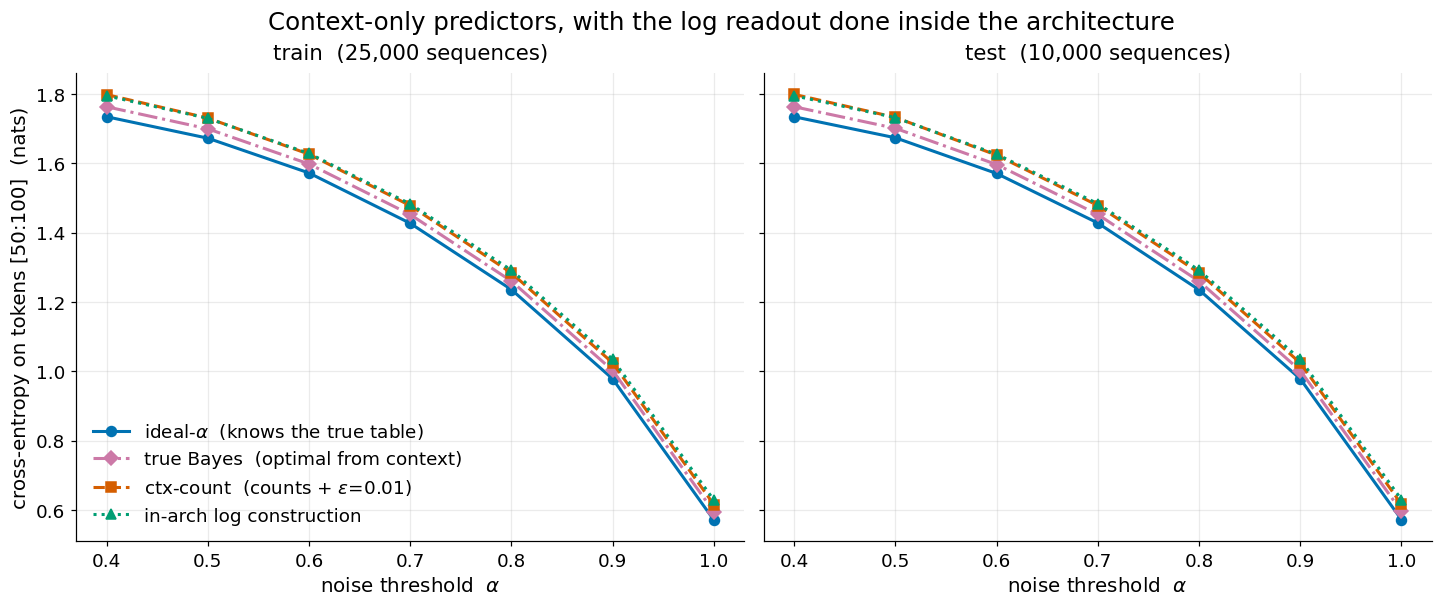

In [10]:
SERIES = {
    'ideal':        dict(color='#0072B2', marker='o', ls='-',
                         label=r'ideal-$\alpha$  (knows the true table)'),
    'bayes':        dict(color='#CC79A7', marker='D', ls='-.',
                         label='true Bayes  (optimal from context)'),
    'ctx':          dict(color='#D55E00', marker='s', ls='--',
                         label=rf'ctx-count  (counts + $\varepsilon$={EPS})'),
    'construction': dict(color='#009E73', marker='^', ls=':',
                         label='in-arch log construction'),
}

fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.4), sharey=True)
for ax, split in zip(axes, SPLITS):
    for k in KEYS:
        st = SERIES[k]
        ax.plot(THRESHOLDS, CE[split][k], color=st['color'], marker=st['marker'],
                ls=st['ls'], lw=2.0, ms=6.5, label=st['label'])
    n_seq = load_blob(split, THRESHOLDS[0])['x'].shape[0]
    ax.set_title(f'{split}  ({n_seq:,} sequences)')
    ax.set_xlabel(r'noise threshold  $\alpha$')
    ax.set_xticks(THRESHOLDS)
axes[0].set_ylabel(f'cross-entropy on tokens [{TOKEN_START}:{TOKEN_END}]  (nats)')
axes[0].legend(loc='lower left')
fig.suptitle('Context-only predictors, with the log readout done inside the architecture')
fig.savefig(os.path.join(ARTIFACTS, 'ce_vs_alpha_train_test.png'), bbox_inches='tight')
plt.show()

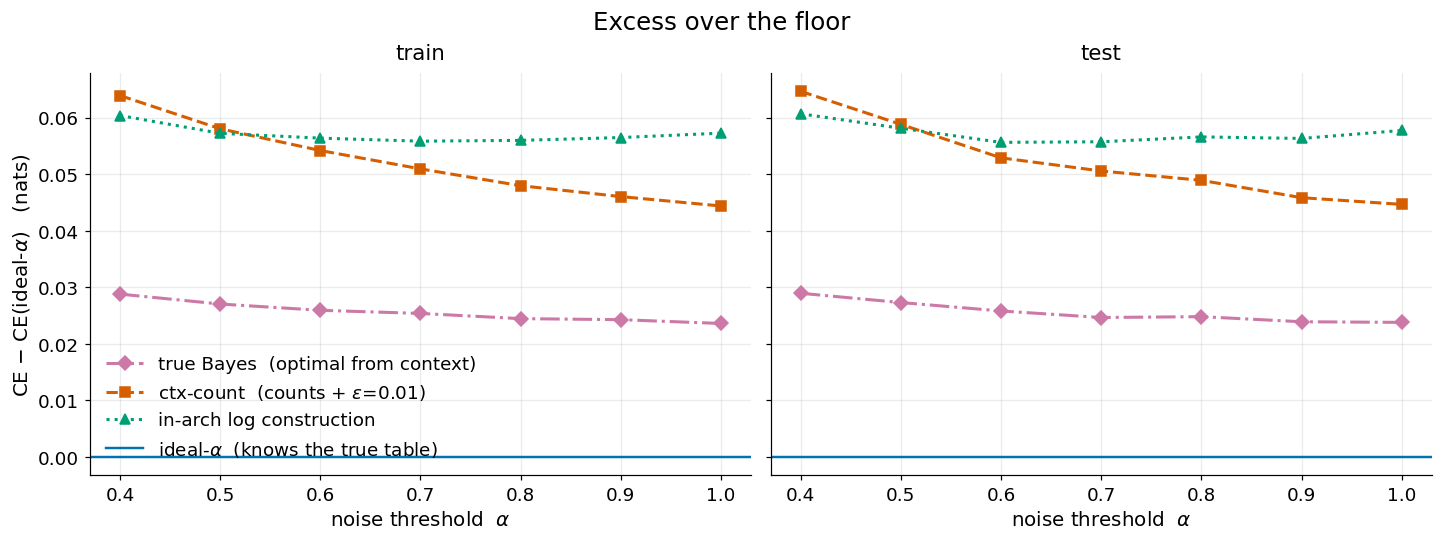

In [11]:
# ── the same thing as excess CE over ideal-alpha, where the ordering is actually readable ──
fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.8), sharey=True)
for ax, split in zip(axes, SPLITS):
    base = np.array(CE[split]['ideal'])
    for k in ['bayes', 'ctx', 'construction']:
        st = SERIES[k]
        ax.plot(THRESHOLDS, np.array(CE[split][k]) - base, color=st['color'],
                marker=st['marker'], ls=st['ls'], lw=2.0, ms=6.5, label=st['label'])
    ax.axhline(0, color='#0072B2', lw=1.6, label=SERIES['ideal']['label'])
    ax.set_title(split); ax.set_xlabel(r'noise threshold  $\alpha$')
    ax.set_xticks(THRESHOLDS)
axes[0].set_ylabel(r'CE $-$ CE(ideal-$\alpha$)   (nats)')
axes[0].legend()
fig.suptitle('Excess over the floor')
fig.savefig(os.path.join(ARTIFACTS, 'excess_ce_train_test.png'), bbox_inches='tight')
plt.show()

In [12]:
# ── the numbers ─────────────────────────────────────────────────────────────────────────
import csv
rows = []
hdr = f'{"thr":>5s} | ' + ' | '.join(
    f'{n:>21s}' for n in ['ideal', 'bayes', 'ctx-count', 'construction'])
print(hdr); print(f'{"":>5s} | ' + ' | '.join(f'{"train":>10s} {"test":>10s}' for _ in KEYS))
print('-' * len(hdr))
for i, thr in enumerate(THRESHOLDS):
    r = {'threshold': thr}
    cells_ = []
    for n in KEYS:
        r[f'{n}_train'] = round(CE['train'][n][i], 5)
        r[f'{n}_test']  = round(CE['test'][n][i], 5)
        cells_.append(f"{CE['train'][n][i]:10.4f} {CE['test'][n][i]:10.4f}")
    rows.append(r)
    print(f'{thr:5.1f} | ' + ' | '.join(cells_))

csv_path = os.path.join(ARTIFACTS, 'baselines.csv')
with open(csv_path, 'w', newline='') as fh:
    wtr = csv.DictWriter(fh, fieldnames=list(rows[0])); wtr.writeheader(); wtr.writerows(rows)
print(f'\nwrote {csv_path}')

print('\nconstruction - ctx-count  (negative = the in-arch construction is better):')
for split in SPLITS:
    d = np.array(CE[split]['construction']) - np.array(CE[split]['ctx'])
    print(f'  {split:5s} ' + '  '.join(f'{t}:{v:+.4f}' for t, v in zip(THRESHOLDS, d)))
print('\nconstruction - true Bayes  (how much the in-arch readout leaves on the table):')
for split in SPLITS:
    d = np.array(CE[split]['construction']) - np.array(CE[split]['bayes'])
    print(f'  {split:5s} ' + '  '.join(f'{t}:{v:+.4f}' for t, v in zip(THRESHOLDS, d)))

  thr |                 ideal |                 bayes |             ctx-count |          construction
      |      train       test |      train       test |      train       test |      train       test
-----------------------------------------------------------------------------------------------------
  0.4 |     1.7339     1.7338 |     1.7627     1.7627 |     1.7978     1.7984 |     1.7943     1.7944
  0.5 |     1.6721     1.6732 |     1.6991     1.7005 |     1.7301     1.7320 |     1.7293     1.7313
  0.6 |     1.5718     1.5703 |     1.5977     1.5961 |     1.6259     1.6232 |     1.6281     1.6259
  0.7 |     1.4266     1.4274 |     1.4520     1.4520 |     1.4776     1.4779 |     1.4825     1.4831
  0.8 |     1.2355     1.2348 |     1.2599     1.2596 |     1.2834     1.2837 |     1.2915     1.2914
  0.9 |     0.9782     0.9781 |     1.0024     1.0020 |     1.0242     1.0239 |     1.0346     1.0344
  1.0 |     0.5713     0.5721 |     0.5949     0.5959 |     0.6157     0.6168 |   

## 6. How much does $\varepsilon$ matter?

$\varepsilon$ is the construction's only free parameter. Section 2.2 established that the
network reproduces $\alpha(f_v+\varepsilon)/\sum_u(f_u+\varepsilon)$ to $10^{-6}$ nats, so the
sweep can be run on the closed form over a cached $f$ — one forward pass instead of one per
$\varepsilon$. The value used above is marked.

  thr  best eps   CE(best)   CE(eps=0.01)   gain


  0.4     0.010     1.7954       1.7954 +0.0000


  0.5     0.010     1.7290       1.7290 +0.0000


  0.6     0.010     1.6259       1.6259 +0.0000


  0.7     0.003     1.4809       1.4815 +0.0006


  0.8     0.003     1.2859       1.2892 +0.0033


  0.9     0.003     1.0308       1.0360 +0.0052


  1.0     0.003     0.6235       0.6306 +0.0071


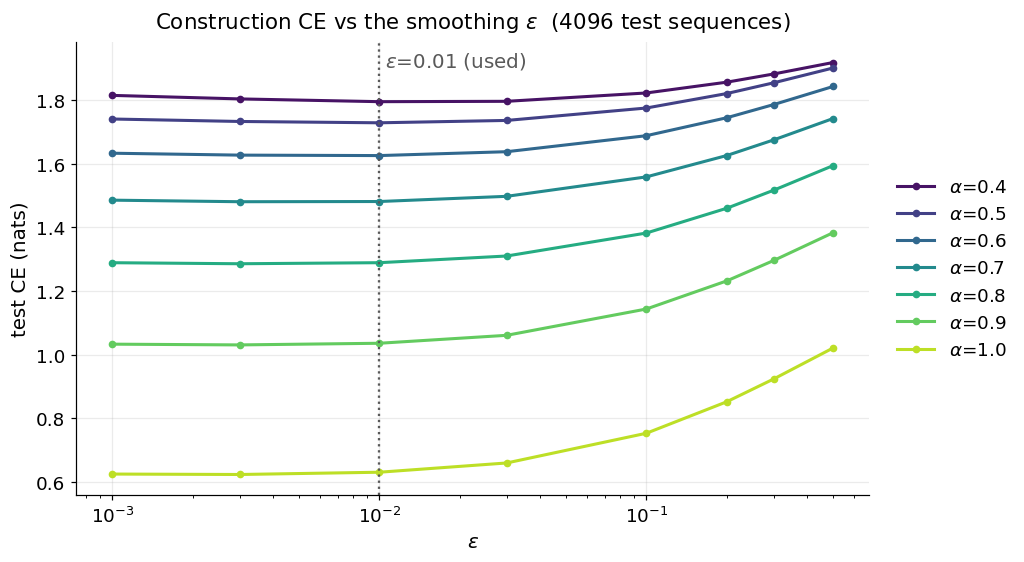

In [13]:
@torch.no_grad()
def cached_f(blob, dev=DEV, batch=FWD_BATCH, n_max=4096):
    '''The frequencies the induction circuit emits, once, so eps can be swept cheaply.'''
    m = build_construction_model(0.5, dev=dev)
    with torch.no_grad():                     # bypass FFN + readout: read f directly
        m.ff1.weight.zero_(); m.ff1.bias.zero_()
        m.ff2.weight.zero_(); m.ff2.bias.zero_()
        m.fc_out.weight.zero_(); m.fc_out.bias.zero_()
        m.fc_out.weight[:V, m.in2:m.in2 + V] = torch.eye(V, device=dev)
    fs = []
    x_all = blob['x'][:n_max]
    for i in range(0, x_all.shape[0], batch):
        fs.append(m(x_all[i:i + batch].to(dev))[:, TOKEN_START:TOKEN_END, :VS].cpu())
    return torch.cat(fs), blob['y'][:n_max, TOKEN_START:TOKEN_END]

EPS_GRID = [0.001, 0.003, 0.01, 0.03, 0.1, 0.2, 0.3, 0.5]
fig, ax = plt.subplots(figsize=(9.2, 5.0))
ramp = plt.cm.viridis(np.linspace(0.05, 0.9, len(THRESHOLDS)))
print(f'{"thr":>5s}  best eps   CE(best)   CE(eps={EPS})   gain')
for j, thr in enumerate(THRESHOLDS):
    blob = load_blob('test', thr)
    f, y = cached_f(blob)
    ces = []
    for e in EPS_GRID:
        psig = thr * (f + e) / (f + e).sum(-1, keepdim=True)
        pn = torch.full(psig.shape[:-1] + (N_NOISE,),
                        (1 - thr) / N_NOISE if thr < 1 else 0.0)
        p = torch.cat([psig, pn], -1)
        ces.append(float(-torch.log(p.gather(-1, y.unsqueeze(-1)).clamp_min(1e-12)).mean()))
    ax.plot(EPS_GRID, ces, marker='o', ms=4, color=ramp[j], label=rf'$\alpha$={thr}')
    b = int(np.argmin(ces)); cur = ces[EPS_GRID.index(EPS)]
    print(f'{thr:5.1f} {EPS_GRID[b]:9.3f} {ces[b]:10.4f} {cur:12.4f} {cur - ces[b]:+7.4f}')
ax.axvline(EPS, color='0.35', ls=':', lw=1.5)
ax.annotate(rf'$\varepsilon$={EPS} (used)', xy=(EPS, ax.get_ylim()[1]),
            xytext=(4, -16), textcoords='offset points', color='0.35')
ax.set_xscale('log'); ax.set_xlabel(r'$\varepsilon$'); ax.set_ylabel('test CE (nats)')
ax.set_title(r'Construction CE vs the smoothing $\varepsilon$  (4096 test sequences)')
ax.legend(loc='center left', bbox_to_anchor=(1.015, 0.5))   # outside: the curves fill the axes
fig.savefig(os.path.join(ARTIFACTS, 'eps_sweep.png'), bbox_inches='tight')
plt.show()

## 7. What this notebook establishes

1. The GELU log core represents $\log(f+\varepsilon)$ on $f\in[0,1]$ to **$\sim10^{-4}$ nats**,
   monotonically — checked on a dense grid *and* on every frequency $a/b$ the induction head can
   actually emit. Geometric knots are what make this work; the uniform-knot scheme in the grid
   above is two and a half orders of magnitude worse before Adam even gets a chance to diverge
   on it.
2. The construction runs **entirely inside `SimplifiedTransformerMLP`** — attention circuit,
   residual FFN, `fc_out` selector, the model's own softmax. Its CE matches the closed-form
   predictor it is meant to implement to $\sim10^{-6}$ nats, so the network, not the notebook,
   is doing the arithmetic.
3. $\sum_v f_v \equiv 1$, so the whole $\alpha/(1-\alpha)$ split is carried by **one constant**
   in `fc_out.bias` — no per-context normalisation is needed, and none is used.

Still outstanding (deliberately not touched here): folder 12/14's `train.py` installs the
**broken** core into every trained model (`freeze_fit_steps=2000`, diverging to MSE 4.0e+02).
Every trained run in those folders shares the identical broken readout, so comparisons *within*
those projects remain apples-to-apples, but any mechanistic reading of what the trained `fc_out`
learned is measured against a readout that is not a log. Fixing that means retraining.